<a href="https://colab.research.google.com/github/ZiyuCao421/Papers-and-Research/blob/main/Mathematics/Number-Theory/Prime-Residue-Geometry-Lab/notebooks/Prime_Residue_Geometry_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prime Residue Geometry Lab
### 全素数余数空间的二维几何投影：从数字编码到光滑曲线

**研究型可运行实验 · Python / Jupyter / Google Colab**  
作者可自由修改实验参数、增加自己的猜想。所有结论需区分**恒等式**、**数值实验**与**尚未证明的猜想**。

## 研究目标

对前 $k$ 个素数 $p_1,\ldots,p_k$，定义

$$
\Phi_k(n)=\sum_{j=1}^{k} w_j\exp\!\left(\frac{2\pi i(n\bmod p_j)}{p_j}\right),\qquad n\in\mathbb Z.
$$

把 $\operatorname{Re}\Phi_k(n)$、$\operatorname{Im}\Phi_k(n)$ 分别作为平面坐标。

**关键恒等式**：由于 $e^{2\pi i(n\bmod p)/p}=e^{2\pi i n/p}$，上面的整数点恰好是光滑参数曲线

$$
F_k(t)=\sum_{j=1}^{k}w_j e^{2\pi i t/p_j},\quad t\in\mathbb R
$$

在整数 $t=n$ 上的采样。对于有限 $k$，$F_k$ 为 $C^\infty$，并且以素数连乘 $M_k=\prod_{j=1}^k p_j$ 为一个周期（不一定是最小周期，零权重等情形尤其如此）。

> **请注意**：这个光滑性来自我们选定的指数映射，不能据此声称证明了素数分布的光滑性，更不能作为黎曼猜想的证明。

**Notebook 导览**：01 环境与定义 → 02 二维投影 → 03 光滑延拓 → 04 周期和频谱 → 05 素数/合数对照 → 06 改变素数数量 → 07 可选交互。

## 01 · 环境与核心定义

依赖仅为 `numpy`、`matplotlib`；附加的交互滑块需要 `ipywidgets`，不是运行实验的必要条件。

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.figsize': (11, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18,
})
SEED = 20261123
rng = np.random.default_rng(SEED)
print('NumPy:', np.__version__, '| Ready')

NumPy: 2.4.6 | Ready


In [2]:
def first_primes(k):
    """Generate the first k prime numbers (no optional dependencies)."""
    out = []
    candidate = 2
    while len(out) < k:
        if all(candidate % p != 0 for p in out if p*p <= candidate):
            out.append(candidate)
        candidate += 1
    return np.asarray(out, dtype=int)

def prime_sieve(N):
    """Boolean vector indexed from 0 to N; True exactly at primes."""
    mask = np.ones(N+1, dtype=bool)
    mask[:2] = False
    for p in range(2, math.isqrt(N)+1):
        if mask[p]:
            mask[p*p::p] = False
    return mask

def normalized_weights(primes, scheme='uniform'):
    p = np.asarray(primes, dtype=float)
    if scheme == 'uniform':
        w = np.ones(len(p))
    elif scheme == 'inverse_sqrt_prime':
        w = 1 / np.sqrt(p)
    elif scheme == 'geometric':
        w = .5 ** np.arange(len(p), dtype=float)
    else:
        raise ValueError(f'Unknown weighting: {scheme}')
    return w / np.sum(w)

def residue_projection(n, primes, weights=None):
    """Return complex points Phi_k(n). Vectorized, n may be scalars/arrays."""
    n = np.atleast_1d(np.asarray(n, dtype=np.int64))
    p = np.asarray(primes, dtype=int)
    w = normalized_weights(p) if weights is None else np.asarray(weights, dtype=float)
    if len(w) != len(p):
        raise ValueError('weights and primes must have the same length')
    theta = 2 * np.pi * np.mod(n[:, None], p[None, :]) / p[None, :]
    return np.exp(1j * theta) @ w

def smooth_extension(t, primes, weights=None):
    """Continuous-time C-infinity extension F_k(t)."""
    t = np.atleast_1d(np.asarray(t, dtype=float))
    p = np.asarray(primes, dtype=float)
    w = normalized_weights(p) if weights is None else np.asarray(weights, dtype=float)
    return np.exp(2j*np.pi*t[:, None]/p[None, :]) @ w

P8 = first_primes(8)
assert P8.tolist() == [2, 3, 5, 7, 11, 13, 17, 19]
assert prime_sieve(10).nonzero()[0].tolist() == [2, 3, 5, 7]
assert np.allclose(residue_projection(np.arange(1, 200), P8[:4]),
                   smooth_extension(np.arange(1, 200), P8[:4]), atol=1e-13)
print('First 8 primes:', P8, '| all initial tests passed')

First 8 primes: [ 2  3  5  7 11 13 17 19] | all initial tests passed


## 02 · 不同数量素数生成的二维点云

保持输入自然数 $n=1,\ldots,N$ 不变，只改变参与编码的素数数量 $k$。橙色为素数，灰色为非素数（含 1）。所有图像使用**相同坐标尺度**，便于真实比较。

**观察任务**：图案是否重复？改变 $k$ 后是否出现新的角度和群集？它们是否由模运算直接决定？

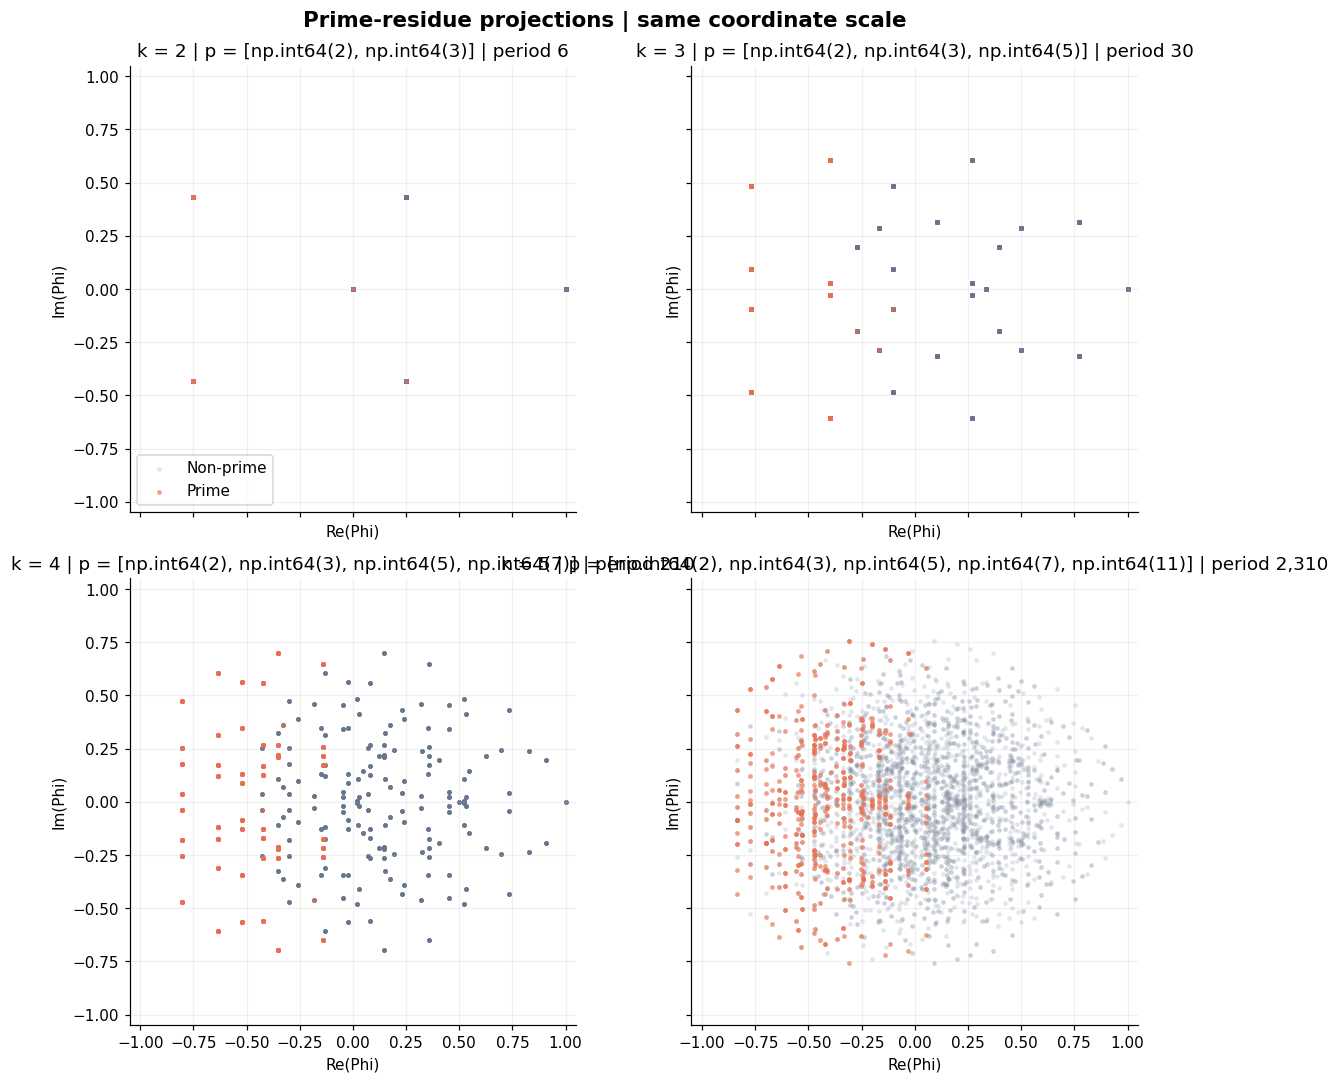

In [3]:
N = 3500
n = np.arange(1, N + 1)
isprime = prime_sieve(N)[1:]
fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), [2, 3, 4, 5]):
    p = first_primes(k)
    z = residue_projection(n, p)
    ax.scatter(z.real[~isprime], z.imag[~isprime], s=9, alpha=.18,
               c='#64748b', linewidths=0, label='Non-prime')
    ax.scatter(z.real[isprime], z.imag[isprime], s=10, alpha=.65,
               c='#e76f51', linewidths=0, label='Prime')
    ax.set_title(f'k = {k} | p = {list(p)} | period {math.prod(p):,}')
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel('Re(Phi)'); ax.set_ylabel('Im(Phi)')
axes[0,0].legend(loc='lower left', frameon=True)
fig.suptitle('Prime-residue projections | same coordinate scale', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## 03 · 整数采样点与光滑延拓

对有限 $k$，$F_k(t)$ 是三角多项式，因此具有任意阶导数：

$$
F_k^{(m)}(t)=\sum_{j=1}^{k}w_j\left(\frac{2\pi i}{p_j}\right)^m e^{2\pi i t/p_j}.
$$

下图中的蓝线是连续时间参数曲线，橙点是 **相同曲线在整数时间处的采样**，不是另一次拟合。视觉上存在交叉或形状复杂，不影响其作为参数曲线的光滑性。

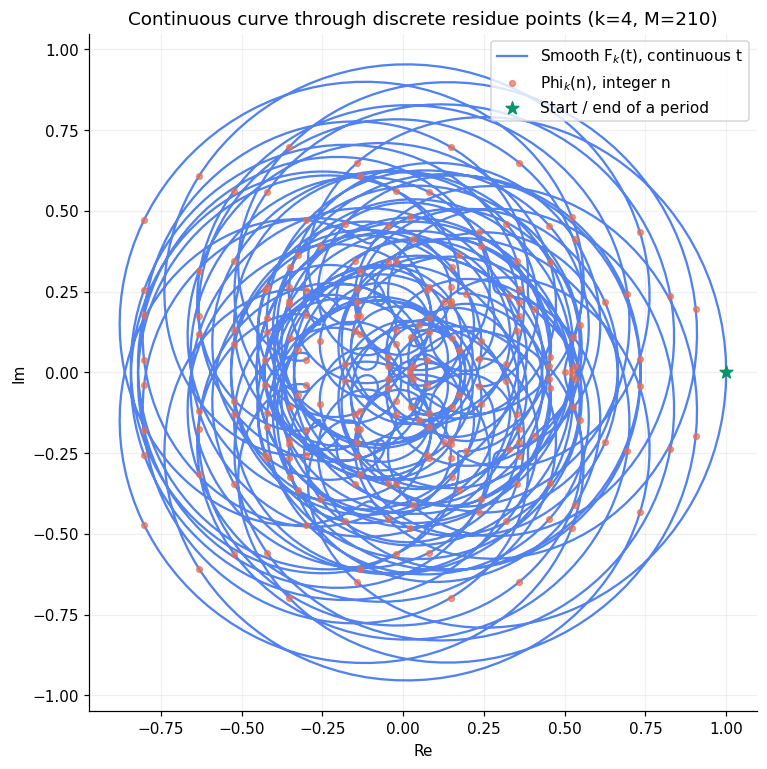

Max integer-vs-continuous difference: 3.7004626108571166e-14


In [4]:
k = 4
p = first_primes(k)
M = math.prod(p)
t = np.linspace(0, M, 8000)
z_cont = smooth_extension(t, p)
n_int = np.arange(0, M + 1)
z_int = residue_projection(n_int, p)
fig, ax = plt.subplots(figsize=(9, 8))
ax.plot(z_cont.real, z_cont.imag, color='#2563eb', lw=1.5, alpha=.8,
        label=r'Smooth F$_k$(t), continuous t')
ax.scatter(z_int.real, z_int.imag, s=14, color='#e76f51', alpha=.68,
           zorder=4, label=r'Phi$_k$(n), integer n')
ax.scatter([z_cont.real[0]], [z_cont.imag[0]], s=75, marker='*', color='#059669',
           zorder=5, label='Start / end of a period')
ax.set_aspect('equal', adjustable='box'); ax.set_xlabel('Re'); ax.set_ylabel('Im')
ax.set_title(f'Continuous curve through discrete residue points (k={k}, M={M})')
ax.legend(); plt.show()
print('Max integer-vs-continuous difference:',
      np.max(np.abs(z_int - smooth_extension(n_int, p))))

## 04 · 周期性检验与频谱分析

令 $M=\prod_{j=1}^{k}p_j$。对每个整数 $n$，

$$
\Phi_k(n+M)=\Phi_k(n).
$$

因为 $M/p_j$ 都是整数，光滑延拓也满足 $F_k(t+M)=F_k(t)$（实数 $t$ 也成立）。这说明在有限 $k$ 时，重复图案是**严格必然的周期**。

更进一步，$F_k(t)$ 恰好是若干复指数的叠加。对一个完整周期做离散傅里叶变换，理论峰值频率为 $1/p_j$，其离散索引为 $M/p_j$。

Primes: [2, 3, 5, 7] | primorial period: 210
max |Phi(n+M) - Phi(n)|: 0.0


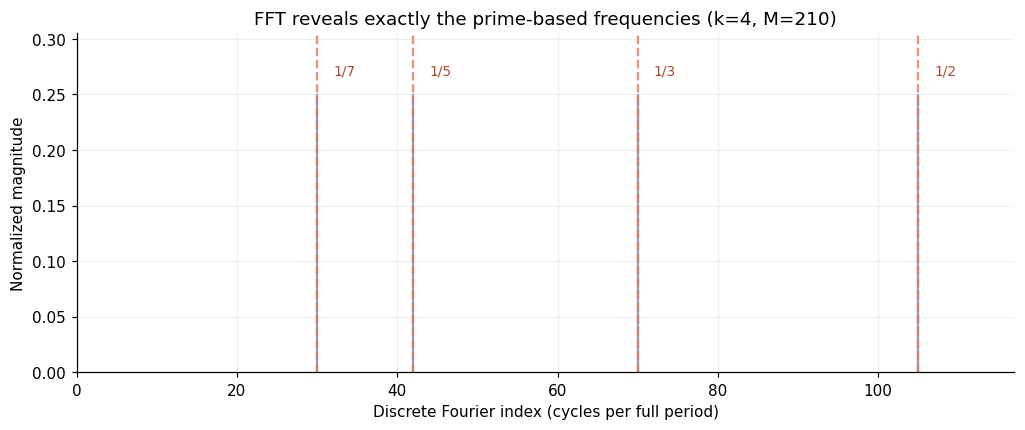

In [5]:
k = 4
p = first_primes(k)
M = math.prod(p)
test = np.array([1, 11, 47, 125, 999, 2026], dtype=int)
z0 = residue_projection(test, p)
z1 = residue_projection(test + M, p)
print('Primes:', p.tolist(), '| primorial period:', M)
print('max |Phi(n+M) - Phi(n)|:', np.max(np.abs(z1-z0)))
assert np.allclose(z0, z1, atol=1e-13)

n_one_period = np.arange(M)
z = residue_projection(n_one_period, p)
spectrum = np.abs(np.fft.fft(z)) / M
fig, ax = plt.subplots(figsize=(11, 4))
ax.stem(np.arange(M), spectrum, linefmt='#94a3b8', markerfmt=' ', basefmt=' ')
for pj in p:
    idx = M // pj
    ax.axvline(idx, color='#e76f51', ls='--', alpha=.75)
    ax.text(idx + 2, spectrum[idx] + .018, f'1/{pj}', color='#ae4b2e', fontsize=9)
ax.set_xlim(0, M//2+12)
ax.set_ylim(0, max(spectrum)*1.22)
ax.set_xlabel('Discrete Fourier index (cycles per full period)')
ax.set_ylabel('Normalized magnitude')
ax.set_title('FFT reveals exactly the prime-based frequencies (k=4, M=210)')
plt.show()

## 05 · 比较素数与合数：避免平凡的整除性泄漏

假如使用 $2,3,5,7$ 建立编码，那么除了这些小素数以外，其他素数都与 $M=210$ 互素。直接把全部素数与全部合数进行分类，将使编码轻易泄露“小素数整除性”，但这不算深刻发现。

因此我们设置更公平的实验：

1. 只考虑 $n>p_k^2$；
2. 只考虑 $\gcd(n,M)=1$ 的整数；
3. 在这一“通过小素数筛选”的群体里，比较素数与合数的几何均值差；
4. 用固定随机种子的**标签置换**构造一个初步随机对照。

注意：有限样本的置换检验是探索性统计工具；它不能证明数论规律，也不能排除范围效应、素数计数偏差及其他系统性影响。

M=210; eligible=4560; primes=2247; composites=2313
Observed complex-mean difference: 0.003186
Exploratory permutation p-value: 0.9301 (1000 permutations)


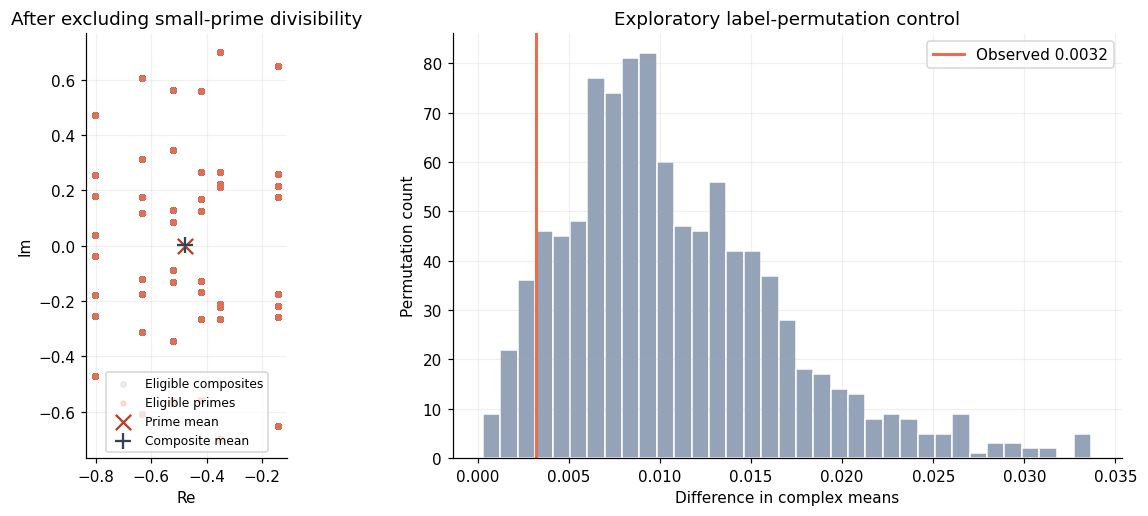

In [6]:
N = 20000
k = 4
p = first_primes(k)
M = math.prod(p)
n = np.arange(1, N + 1)
prime_mask = prime_sieve(N)[1:]
valid = (n > int(p[-1]) ** 2) & (np.gcd(n, M) == 1)
n_valid = n[valid]
labels = prime_mask[valid]
z = residue_projection(n_valid, p)

prime_z, composite_z = z[labels], z[~labels]
stat = float(abs(prime_z.mean() - composite_z.mean()))
permutations = 1000
rng = np.random.default_rng(SEED)
null = np.empty(permutations)
for i in range(permutations):
    shuffled = rng.permutation(labels)
    null[i] = abs(z[shuffled].mean() - z[~shuffled].mean())
pval = (1 + np.count_nonzero(null >= stat)) / (permutations + 1)
print(f'M={M}; eligible={len(n_valid)}; primes={labels.sum()}; composites={(~labels).sum()}')
print(f'Observed complex-mean difference: {stat:.6f}')
print(f'Exploratory permutation p-value: {pval:.4f} ({permutations} permutations)')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(composite_z.real, composite_z.imag, c='#64748b', alpha=.12, s=12,
                label='Eligible composites')
axes[0].scatter(prime_z.real, prime_z.imag, c='#e76f51', alpha=.2, s=10,
                label='Eligible primes')
axes[0].scatter([prime_z.real.mean()], [prime_z.imag.mean()], s=100, marker='x',
                c='#bb3e27', label='Prime mean')
axes[0].scatter([composite_z.real.mean()], [composite_z.imag.mean()], s=110, marker='+',
                c='#334155', label='Composite mean')
axes[0].set_title('After excluding small-prime divisibility')
axes[0].set_aspect('equal', adjustable='box'); axes[0].legend(fontsize=8)
axes[0].set_xlabel('Re'); axes[0].set_ylabel('Im')
axes[1].hist(null, bins=35, color='#94a3b8', edgecolor='white')
axes[1].axvline(stat, c='#e76f51', lw=2, label=f'Observed {stat:.4f}')
axes[1].set_xlabel('Difference in complex means')
axes[1].set_ylabel('Permutation count')
axes[1].set_title('Exploratory label-permutation control')
axes[1].legend()
plt.tight_layout(); plt.show()

## 06 · 随素数数量增加的极限：为什么可能变成一个点？

考虑等权重平均：

$$
F_k(t)=\frac{1}{k}\sum_{j=1}^{k} e^{2\pi i t/p_j}.
$$

当 $k\to\infty$、**固定 $t$** 时，$p_j\to\infty$，故 $e^{2\pi i t/p_j}\to1$。由 Cesàro 平均定理，$F_k(t)\to1$，而且这一收敛在每个固定的有界 $t$ 区间上一致成立。

因此，简单增加素数个数，可能得到**退化的常数极限**，而不是更丰富的几何曲线。这是研究中应该主动查找的反例。

下方我们测量 $t\in[0,30]$ 上到复数 1 的最大距离。它是数值迹象，而非对收敛速度的严格证明。

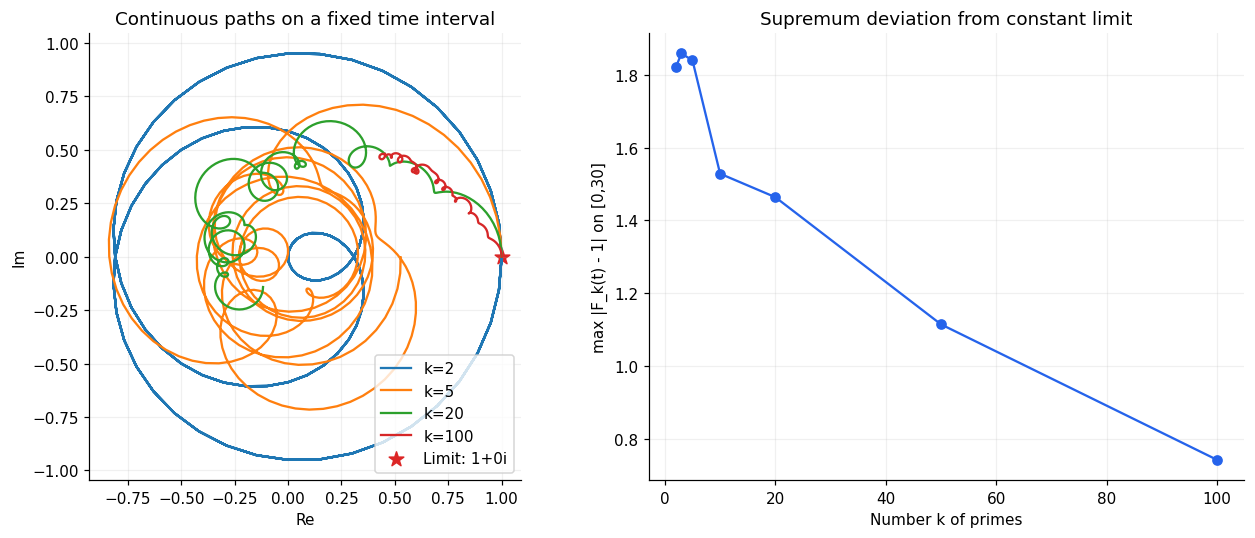

max deviations: {2: np.float64(1.82178), 3: np.float64(1.85893), 5: np.float64(1.83994), 10: np.float64(1.52831), 20: np.float64(1.46378), 50: np.float64(1.11404), 100: np.float64(0.7414)}


In [7]:
T = np.linspace(0, 30, 501)
K_list = [2, 3, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
deviations = []
for k in K_list:
    z = smooth_extension(T, first_primes(k))
    deviations.append(float(np.max(np.abs(z-1))))
    if k in [2, 5, 20, 100]:
        axes[0].plot(z.real, z.imag, lw=1.5, label=f'k={k}')
axes[0].scatter([1], [0], marker='*', c='#dc2626', s=100, label='Limit: 1+0i')
axes[0].set_aspect('equal', adjustable='box')
axes[0].set_title('Continuous paths on a fixed time interval')
axes[0].set_xlabel('Re'); axes[0].set_ylabel('Im'); axes[0].legend()
axes[1].plot(K_list, deviations, 'o-', color='#2563eb')
axes[1].set_title('Supremum deviation from constant limit')
axes[1].set_xlabel('Number k of primes')
axes[1].set_ylabel('max |F_k(t) - 1| on [0,30]')
plt.tight_layout(); plt.show()
print('max deviations:', dict(zip(K_list, np.round(deviations, 5))))

## 07 · 可选：Notebook 内交互控件

在 JupyterLab / Notebook 中安装 `ipywidgets` 后，可以在这里直接用滑块改变 $k$、$N$ 和权重。**未安装也不影响前 6 组实验正常运行**。附带的离线 HTML 页面不需要安装任何 Python 依赖。

In [8]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Optional ipywidgets not installed. Static experiments above are complete.')
    print('To enable notebook sliders: %pip install ipywidgets')
else:
    def explore(k=4, N=1200, weighting='uniform', connect=False):
        p = first_primes(k)
        x = np.arange(1, N + 1)
        z = residue_projection(x, p, normalized_weights(p, weighting))
        mask = prime_sieve(N)[1:]
        fig, ax = plt.subplots(figsize=(7, 6))
        if connect:
            ax.plot(z.real, z.imag, lw=.6, alpha=.45, color='#0f766e')
        ax.scatter(z.real[~mask], z.imag[~mask], s=11, alpha=.2, c='#64748b')
        ax.scatter(z.real[mask], z.imag[mask], s=13, alpha=.8, c='#e76f51')
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlim(-1.07, 1.07); ax.set_ylim(-1.07, 1.07)
        ax.set_title(f'k={k}; prime period={math.prod(p):,}; N={N}')
        ax.set_xlabel('Re'); ax.set_ylabel('Im')
        plt.show()
    widgets.interact(
        explore,
        k=widgets.IntSlider(value=4, min=2, max=8, step=1, continuous_update=False),
        N=widgets.IntSlider(value=1200, min=200, max=5000, step=200, continuous_update=False),
        weighting=widgets.Dropdown(options=['uniform','inverse_sqrt_prime','geometric'],
                                    value='uniform'),
        connect=False,
    )

interactive(children=(IntSlider(value=4, continuous_update=False, description='k', max=8, min=2), IntSlider(va…

## 08 · 可证伪研究问题与后续工作

**已严格成立**

- 有限 $k$ 的指数投影可由 $C^\infty$ 曲线 $F_k(t)$ 延拓。
- $\prod_{j=1}^{k}p_j$ 是该投影的一个周期。
- 有限权重对应的频率来自 $1/p_j$。
- 在固定有界时间区间，等权重平均 $F_k$ 随 $k\to\infty$ 一致收敛到常数 1。

**值得继续研究，但尚未通过本实验确立**

- 若让时间 $t$ 随最大素数伸缩（例如 $t\mapsto t p_k$），是否出现非平凡的极限？
- 在控制整除性和剩余类分布后，素数与合数投影是否具有可复现的差异？
- 用不等权重、不同嵌入方式（保留各素数相位信息）时，是否存在稳定的几何不变量？
- 用混合进制或 p 进距离重新定义“邻近”后，能否形成具有意义的连续性理论？

**常见误区**：轨迹好看 ≠ 新定理；在二维有曲线 ≠ 原始高维信息无损；样本 p 值小 ≠ 证明素数定理/黎曼猜想；$F_k$ 的人为光滑延拓 ≠ 素数分布本身光滑。

**下一步建议**：先改动权重和时间尺度，设计明确的零假设，对多组 $N,k$ 与多个随机种子做复现实验，然后再考虑严格证明。